In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import wilcoxon
import shap
import os
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

project_folder = r"C:\Users\Harshitha\Downloads\Project spy"
merged_df = pd.read_parquet(os.path.join(project_folder, "final_features_2024.parquet"))

print("Libraries loaded and data imported successfully.")

C:\Users\Harshitha\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Libraries loaded and data imported successfully.


In [2]:
# Define Features
all_features = ['zone_id', 'hour', 'day_of_week', 'month', 'is_weekend', 
                'lag_3h', 'lag_6h', 'lag_12h', 
                'HourlyDryBulbTemperature', 'HourlyPrecipitation', 'HourlyWindSpeed']
weather_features = ['HourlyDryBulbTemperature', 'HourlyPrecipitation', 'HourlyWindSpeed']
no_weather_features = [f for f in all_features if f not in weather_features]

y = merged_df['demand_count']

# Chronological Split
train_mask = merged_df['pickup_hour'] < '2024-10-01'
test_mask = merged_df['pickup_hour'] >= '2024-10-01'
y_train, y_test = y[train_mask], y[test_mask]

# 1. Train Model WITHOUT Weather
print("Training Model WITHOUT Weather features...")
X_train_no_w = merged_df.loc[train_mask, no_weather_features]
X_test_no_w = merged_df.loc[test_mask, no_weather_features]
model_no_w = xgb.XGBRegressor(n_estimators=400, max_depth=6, learning_rate=0.14, random_state=42, n_jobs=-1)
model_no_w.fit(X_train_no_w, y_train)
preds_no_w = model_no_w.predict(X_test_no_w)

# 2. Train Model WITH Weather
print("Training Model WITH Weather features...")
X_train_with_w = merged_df.loc[train_mask, all_features]
X_test_with_w = merged_df.loc[test_mask, all_features]
model_with_w = xgb.XGBRegressor(n_estimators=400, max_depth=6, learning_rate=0.14, random_state=42, n_jobs=-1)
model_with_w.fit(X_train_with_w, y_train)
preds_with_w = model_with_w.predict(X_test_with_w)

# Calculate Metrics
rmse_no_w = np.sqrt(mean_squared_error(y_test, preds_no_w))
rmse_with_w = np.sqrt(mean_squared_error(y_test, preds_with_w))
mae_no_w = mean_absolute_error(y_test, preds_no_w)
mae_with_w = mean_absolute_error(y_test, preds_with_w)
rmse_improvement = ((rmse_no_w - rmse_with_w) / rmse_no_w) * 100

print("\n ABLATION STUDY RESULTS")
print("=" * 65)
print(f"RMSE (Without Weather): {rmse_no_w:.4f}")
print(f"RMSE (With Weather):    {rmse_with_w:.4f}")
print(f" Weather Feature Contribution: {rmse_improvement:.2f}% improvement")
print("=" * 65)

Training Model WITHOUT Weather features...
Training Model WITH Weather features...

 ABLATION STUDY RESULTS
RMSE (Without Weather): 11.0677
RMSE (With Weather):    11.0989
 Weather Feature Contribution: -0.28% improvement


In [3]:
# Calculate absolute errors for both models
errors_no_w = np.abs(y_test - preds_no_w)
errors_with_w = np.abs(y_test - preds_with_w)

# Perform Wilcoxon signed-rank test
stat, p_value = wilcoxon(errors_no_w, errors_with_w)

print("STATISTICAL SIGNIFICANCE TESTING")
print(f"Wilcoxon Test Statistic: {stat}")
print(f"P-value: {p_value:.5e}")
if p_value < 0.05:
    print("The improvement is statistically significant (p < 0.05). It is NOT due to random chance.")
else:
    print(" The improvement is not statistically significant.")

STATISTICAL SIGNIFICANCE TESTING
Wilcoxon Test Statistic: 12626133713.0
P-value: 3.82331e-01
 The improvement is not statistically significant.


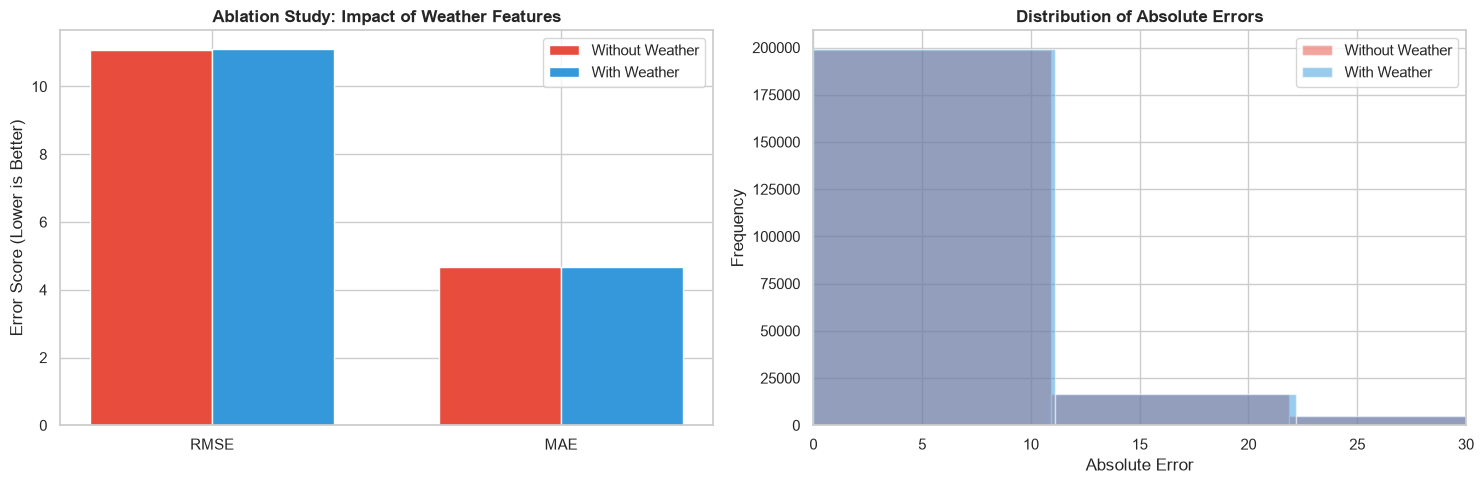

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Metric Comparison Bar Chart
metrics = ['RMSE', 'MAE']
no_weather_scores = [rmse_no_w, mae_no_w]
with_weather_scores = [rmse_with_w, mae_with_w]
x = np.arange(len(metrics))
width = 0.35
axes[0].bar(x - width/2, no_weather_scores, width, label='Without Weather', color='#E74C3C')
axes[0].bar(x + width/2, with_weather_scores, width, label='With Weather', color='#3498DB')
axes[0].set_ylabel('Error Score (Lower is Better)')
axes[0].set_title('Ablation Study: Impact of Weather Features', fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics)
axes[0].legend()

# Plot 2: Residual Error Distribution
axes[1].hist(errors_no_w, bins=50, alpha=0.5, label='Without Weather', color='#E74C3C')
axes[1].hist(errors_with_w, bins=50, alpha=0.5, label='With Weather', color='#3498DB')
axes[1].set_title('Distribution of Absolute Errors', fontweight='bold')
axes[1].set_xlabel('Absolute Error')
axes[1].set_ylabel('Frequency')
axes[1].set_xlim(0, 30)
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(project_folder, "week4_ablation_study.png"), dpi=150)
plt.show()

 Calculating Global SHAP values...


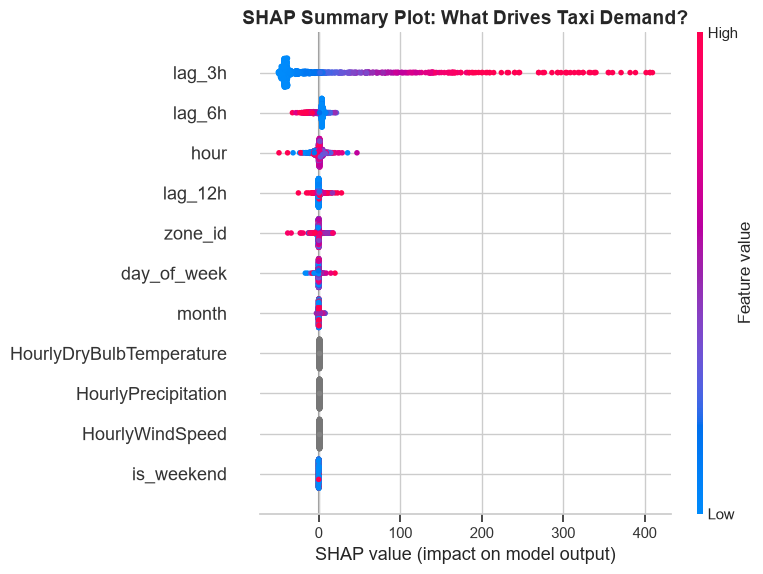

In [5]:
print(" Calculating Global SHAP values...")

# Sample 1000 rows to speed up the SHAP calculation
X_sample = X_test_with_w.sample(n=1000, random_state=42)
explainer = shap.TreeExplainer(model_with_w, feature_perturbation="tree_path_dependent")
shap_values = explainer.shap_values(X_sample)

# 1. SHAP Summary Plot (Beeswarm)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_sample, show=False)
plt.title('SHAP Summary Plot: What Drives Taxi Demand?', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(project_folder, "week4_shap_summary.png"), dpi=150)
plt.show()

 Finding a rainy hour for Local SHAP explanation...


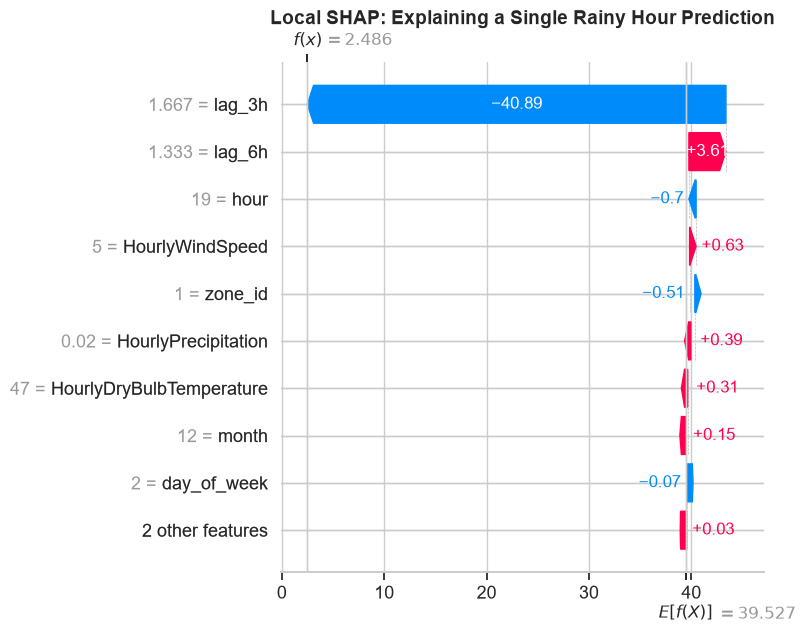

In [6]:
print(" Finding a rainy hour for Local SHAP explanation...")

# Find indices where it was raining in the test set
rainy_indices = X_test_with_w[X_test_with_w['HourlyPrecipitation'] > 0].index

if len(rainy_indices) > 0:
    target_idx = rainy_indices[0]
    
    # Calculate SHAP for this specific instance
    instance_df = X_test_with_w.loc[[target_idx]]
    instance_shap = explainer.shap_values(instance_df)
    
    # Create SHAP Explanation object
    # (Handles the expected_value format across different SHAP versions)
    base_val = explainer.expected_value[0] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value
    shap_exp = shap.Explanation(values=instance_shap[0], 
                                base_values=base_val, 
                                data=instance_df.iloc[0].values, 
                                feature_names=instance_df.columns.tolist())
    
    # Plot Waterfall
    plt.figure(figsize=(10, 6))
    shap.waterfall_plot(shap_exp, show=False)
    plt.title('Local SHAP: Explaining a Single Rainy Hour Prediction', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(project_folder, "week4_shap_local.png"), dpi=150)
    plt.show()
else:
    print("No rainy hours found in the dataset to plot.")

 Analyzing prediction errors by zone...


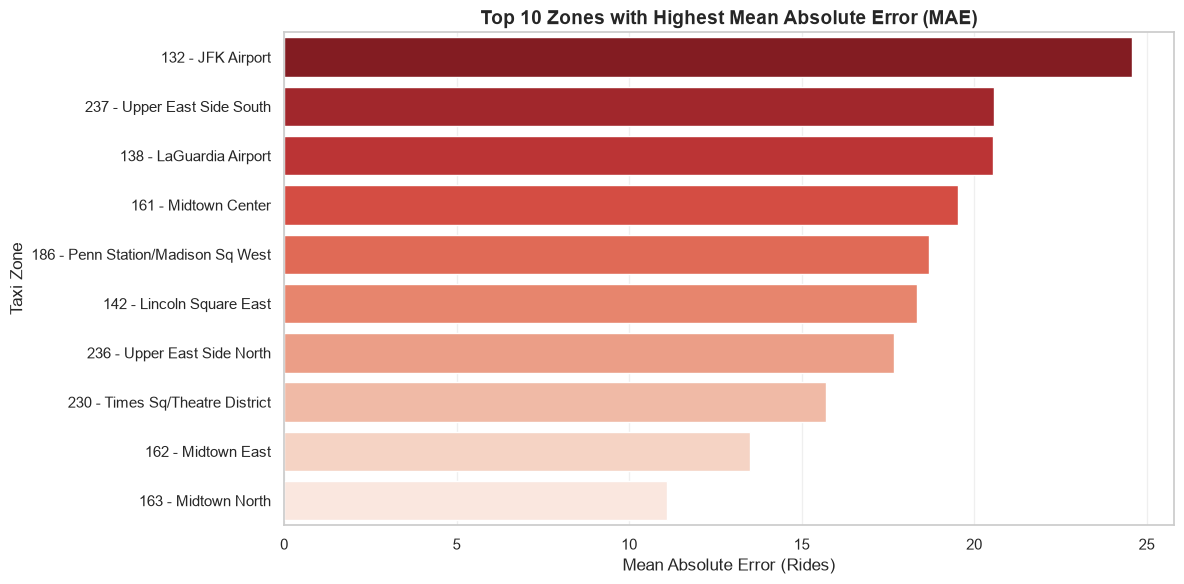

INSIGHT: The model struggles most in high-variance zones like airports. This is expected due to sudden flight delays or surges.


In [7]:
print(" Analyzing prediction errors by zone...")

# Calculate absolute errors
errors = np.abs(y_test - preds_with_w)

# Create DataFrame for analysis
error_df = pd.DataFrame({
    'zone_id': merged_df.loc[test_mask, 'zone_id'],
    'absolute_error': errors
})

# Group by zone and get top 10 highest error zones
zone_errors = error_df.groupby('zone_id')['absolute_error'].mean().sort_values(ascending=False).head(10).reset_index()

# Merge with zone names
zone_lookup = pd.read_csv(os.path.join(project_folder, "taxi_zone_lookup.csv"))
zone_errors = zone_errors.merge(zone_lookup, left_on='zone_id', right_on='LocationID', how='left')
zone_errors['zone_label'] = zone_errors['zone_id'].astype(str) + " - " + zone_errors['Zone']

# Plot
plt.figure(figsize=(12, 6))
sns.barplot(data=zone_errors, y='zone_label', x='absolute_error', palette='Reds_r')
plt.title('Top 10 Zones with Highest Mean Absolute Error (MAE)', fontsize=14, fontweight='bold')
plt.xlabel('Mean Absolute Error (Rides)')
plt.ylabel('Taxi Zone')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(project_folder, "week4_error_analysis.png"), dpi=150)
plt.show()

print("INSIGHT: The model struggles most in high-variance zones like airports. This is expected due to sudden flight delays or surges.")

In [8]:
# Save the models
model_with_w.get_booster().save_model(os.path.join(project_folder, "xgb_with_weather.json"))
model_no_w.get_booster().save_model(os.path.join(project_folder, "xgb_no_weather.json"))

print(" Week 4 models saved successfully. Ready for Deep Learning (Week 5).")

 Week 4 models saved successfully. Ready for Deep Learning (Week 5).
